# U-Net for Three-Class Semantic Segmentation


## 1. Setup and reproducibility

In [ ]:
!pip -q install gdown

import os, random, zipfile, shutil, pathlib, re, json, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42

def set_seed(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download and extract the dataset

In [ ]:
FILE_ID = "1t5Z4ekEWc1jmblaEoh88mtQgMQAhrQjm"
ARCHIVE_PATH = "/content/segmentation_dataset.zip"
DATA_DIR = "/content/segmentation_dataset"

if not os.path.exists(ARCHIVE_PATH):
    import gdown
    url = f"https://drive.google.com/uc?id={FILE_ID}"
    result = gdown.download(url, ARCHIVE_PATH, quiet=False)
    if result is None:
        raise RuntimeError("Automatic download failed. Download the file from the assignment link and upload it to Colab as /content/segmentation_dataset.zip.")

if not os.path.exists(DATA_DIR):
    os.makedirs(DATA_DIR, exist_ok=True)
    try:
        with zipfile.ZipFile(ARCHIVE_PATH, "r") as zf:
            zf.extractall(DATA_DIR)
    except zipfile.BadZipFile:
        raise RuntimeError("The downloaded file is not a ZIP archive. Inspect the downloaded file type and extract it according to its actual format.")

print("Top-level files/folders:")
for p in list(pathlib.Path(DATA_DIR).iterdir())[:30]:
    print(p)

Top-level files/folders:
/content/segmentation_dataset/936


## 3. Inspect and pair images with masks



In [ ]:

import os
import pathlib

DATA_DIR = "/content/segmentation_dataset/936"

IMAGE_DIR = os.path.join(DATA_DIR, "data")
MASK_DIR = os.path.join(DATA_DIR, "mask")

print("Image folder exists:", os.path.isdir(IMAGE_DIR))
print("Mask folder exists:", os.path.isdir(MASK_DIR))

print("Files in data folder:",
      os.listdir(IMAGE_DIR)[:10] if os.path.isdir(IMAGE_DIR) else "Not found")

print("Files in mask folder:",
      os.listdir(MASK_DIR)[:10] if os.path.isdir(MASK_DIR) else "Not found")

Image folder exists: True
Mask folder exists: True
Files in data folder: ['618.png', '808.png', '408.png', '46.png', '631.png', '703.png', '713.png', '162.png', '686.png', '835.png']
Files in mask folder: ['618.png', '808.png', '408.png', '46.png', '631.png', '703.png', '713.png', '162.png', '686.png', '835.png']


### a. Pairing Code

In [ ]:

import pathlib
import os

IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

image_paths = sorted([
    str(p) for p in pathlib.Path(IMAGE_DIR).rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
])

mask_paths = sorted([
    str(p) for p in pathlib.Path(MASK_DIR).rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
])

image_map = {pathlib.Path(p).stem: p for p in image_paths}
mask_map = {pathlib.Path(p).stem: p for p in mask_paths}

common_names = sorted(set(image_map) & set(mask_map))

pairs = [
    (image_map[name], mask_map[name])
    for name in common_names
]

print("Number of images:", len(image_paths))
print("Number of masks:", len(mask_paths))
print("Matched pairs:", len(pairs))
print("First pair:", pairs[0] if pairs else "No pairs found")

assert len(pairs) == 936, "Please check the filenames; not all pairs matched."

Number of images: 936
Number of masks: 936
Matched pairs: 936
First pair: ('/content/segmentation_dataset/936/data/1.png', '/content/segmentation_dataset/936/mask/1.png')


### b. Inspect The Mask

In [ ]:

import numpy as np
from PIL import Image

for image_path, mask_path in pairs[:5]:
    image = Image.open(image_path)
    mask = Image.open(mask_path)

    arr = np.array(mask)

    print("\nImage:", os.path.basename(image_path))
    print("Image size:", image.size, "| Mode:", image.mode)
    print("Mask size:", mask.size, "| Mode:", mask.mode)
    print("Mask shape:", arr.shape)
    print("Unique mask values:", np.unique(arr, axis=0)[:20]
          if arr.ndim == 3 else np.unique(arr))


Image: 1.png
Image size: (480, 352) | Mode: RGB
Mask size: (480, 352) | Mode: L
Mask shape: (352, 480)
Unique mask values: [0 1 2]

Image: 10.png
Image size: (480, 352) | Mode: RGB
Mask size: (480, 352) | Mode: L
Mask shape: (352, 480)
Unique mask values: [0 1]

Image: 100.png
Image size: (480, 352) | Mode: RGB
Mask size: (480, 352) | Mode: L
Mask shape: (352, 480)
Unique mask values: [0 1 2]

Image: 101.png
Image size: (480, 352) | Mode: RGB
Mask size: (480, 352) | Mode: L
Mask shape: (352, 480)
Unique mask values: [0 1 2]

Image: 102.png
Image size: (480, 352) | Mode: RGB
Mask size: (480, 352) | Mode: L
Mask shape: (352, 480)
Unique mask values: [0 1 2]


## 4. Inspect mask encoding and configure preprocessing

In [ ]:
IMG_SIZE = (256, 256)
NUM_CLASSES = 3

MASK_VALUE_TO_CLASS = {
    0: 0,
    1: 1,
    2: 2
}

def load_image(path):
    img = Image.open(path).convert("RGB")
    img = img.resize((IMG_SIZE[1], IMG_SIZE[0]), Image.Resampling.BILINEAR)
    return np.asarray(img, dtype=np.float32) / 255.0   # scale to [0, 1]


def load_mask(path):
    mask_img = Image.open(path).convert("L")

    # Nearest-neighbor interpolation preserves discrete class IDs.
    mask_img = mask_img.resize(
        (IMG_SIZE[1], IMG_SIZE[0]),
        Image.Resampling.NEAREST
    )

    mask = np.asarray(mask_img, dtype=np.uint8)

    unique_values = np.unique(mask)
    unknown = set(unique_values.tolist()) - set(MASK_VALUE_TO_CLASS)

    if unknown:
        raise ValueError(
            f"Unexpected mask values in {path}: {unknown}"
        )

    # Keep labels as integer IDs: 0, 1, 2
    return mask


# Quick check (should print: <class 'numpy.ndarray'> (256, 256) uint8)
_m = load_mask(pairs[0][1])
print(type(_m), _m.shape, _m.dtype)

<class 'numpy.ndarray'> (256, 256) uint8


## 5. Check Class Distribution

In [ ]:

from collections import Counter
import numpy as np

pixel_counts = Counter()

for _, mask_path in pairs:
    mask = np.array(Image.open(mask_path).convert("L"))
    pixel_counts.update(mask.ravel().tolist())

total_pixels = sum(pixel_counts.values())

for class_id in range(3):
    count = pixel_counts[class_id]
    print(
        f"Class ID {class_id}: "
        f"{count:,} pixels ({100 * count / total_pixels:.2f}%)"
    )

Class ID 0: 104,163,282 pixels (65.87%)
Class ID 1: 22,813,874 pixels (14.43%)
Class ID 2: 31,169,404 pixels (19.71%)


## 6. Display Image and its Mask

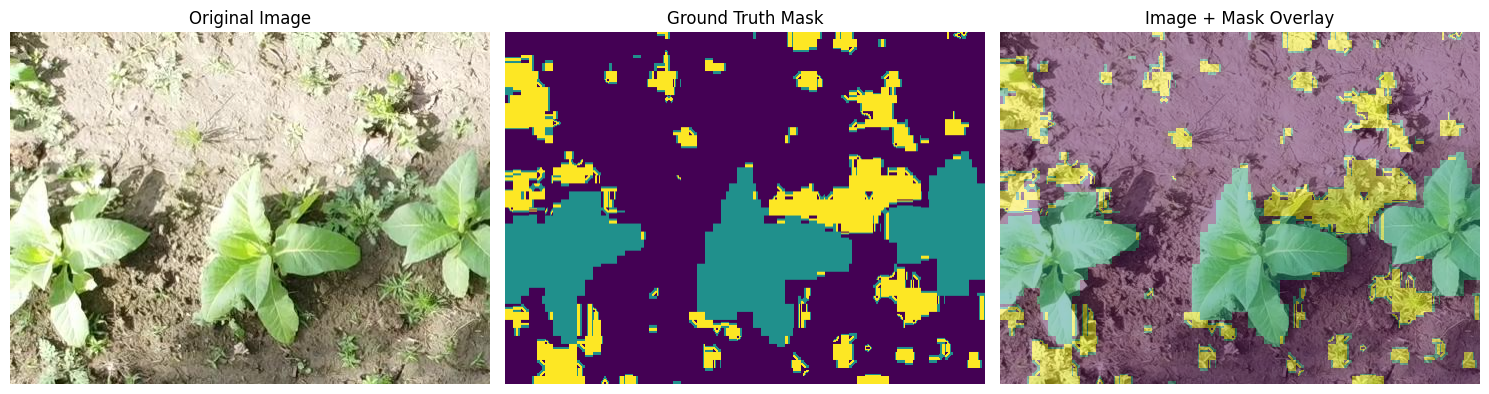

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

image_path, mask_path = pairs[0]

image = np.array(Image.open(image_path).convert("RGB"))
mask = np.array(Image.open(mask_path).convert("L"))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].imshow(image)
ax[0].set_title("Original Image")

ax[1].imshow(mask, cmap="viridis", vmin=0, vmax=2)
ax[1].set_title("Ground Truth Mask")

ax[2].imshow(image)
ax[2].imshow(mask, cmap="viridis", vmin=0, vmax=2, alpha=0.45)
ax[2].set_title("Image + Mask Overlay")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

## 7. Load arrays and create the fixed 80/20 split

Loaded 100/936
Loaded 200/936
Loaded 300/936
Loaded 400/936
Loaded 500/936
Loaded 600/936
Loaded 700/936
Loaded 800/936
Loaded 900/936
X: (936, 256, 256, 3) float32 Y: (936, 256, 256) uint8
Class IDs in all masks: [0 1 2]
Train samples: 748 (79.9%)
Test samples:  188 (20.1%)


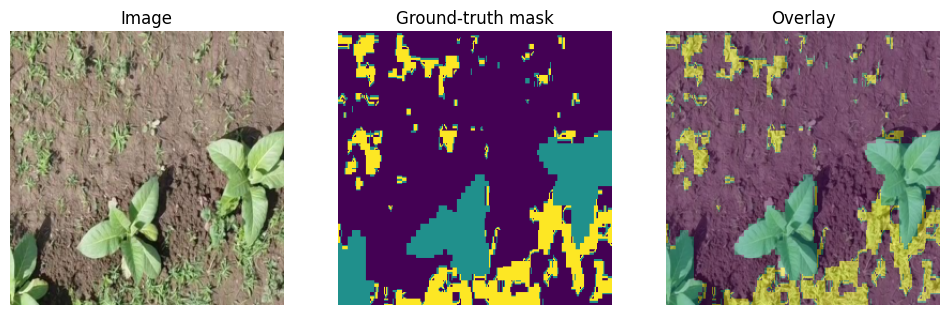

In [ ]:
X_list, Y_list = [], []
for idx, (ip, mp) in enumerate(pairs):
    X_list.append(load_image(ip))
    Y_list.append(load_mask(mp))
    if (idx + 1) % 100 == 0:
        print(f"Loaded {idx+1}/{len(pairs)}")

X = np.stack(X_list).astype(np.float32)
Y = np.stack(Y_list).astype(np.uint8)  # integer class map, shape (N,H,W)
print("X:", X.shape, X.dtype, "Y:", Y.shape, Y.dtype)
print("Class IDs in all masks:", np.unique(Y))

indices = np.arange(len(X))
train_idx, test_idx = train_test_split(indices, test_size=0.20, random_state=SEED, shuffle=True)
X_train, X_test = X[train_idx], X[test_idx]
Y_train, Y_test = Y[train_idx], Y[test_idx]
print(f"Train samples: {len(train_idx)} ({len(train_idx)/len(X):.1%})")
print(f"Test samples:  {len(test_idx)} ({len(test_idx)/len(X):.1%})")

def show_sample(i=0):
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(X_train[i]); ax[0].set_title("Image"); ax[0].axis("off")
    ax[1].imshow(Y_train[i], vmin=0, vmax=2); ax[1].set_title("Ground-truth mask"); ax[1].axis("off")
    ax[2].imshow(X_train[i]); ax[2].imshow(Y_train[i], alpha=0.45, vmin=0, vmax=2); ax[2].set_title("Overlay"); ax[2].axis("off")
    plt.show()
show_sample(0)

## 8. U-Net model with configurable depth

In [ ]:
def conv_block(x, filters, dropout=0.0):
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    if dropout:
        x = layers.Dropout(dropout)(x)
    return x

def build_unet(input_shape=(256, 256, 3), num_classes=3, depth=4, base_filters=16):
    inputs = keras.Input(shape=input_shape)
    x = inputs
    skips = []
    filters = base_filters
    for level in range(depth):
        x = conv_block(x, filters)
        skips.append(x)
        x = layers.MaxPooling2D(pool_size=(2, 2))(x)
        filters *= 2
    x = conv_block(x, filters, dropout=0.1)
    for level in reversed(range(depth)):
        filters //= 2
        x = layers.Conv2DTranspose(filters, 2, strides=2, padding="same")(x)
        x = layers.Concatenate()([x, skips[level]])
        x = conv_block(x, filters)
    outputs = layers.Conv2D(num_classes, 1, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=f"unet_depth_{depth}")

# Loss functions
ce_loss = keras.losses.SparseCategoricalCrossentropy()

def soft_dice_loss(y_true, y_pred, smooth=1e-6):
    # y_true: (B,H,W), y_pred: (B,H,W,C)
    y_true = tf.cast(y_true, tf.int32)
    y_true_oh = tf.one_hot(y_true, depth=NUM_CLASSES)
    axes = (1, 2)
    intersection = tf.reduce_sum(y_true_oh * y_pred, axis=axes)
    denominator = tf.reduce_sum(y_true_oh + y_pred, axis=axes)
    dice = (2.0 * intersection + smooth) / (denominator + smooth)
    return 1.0 - tf.reduce_mean(dice)

def combined_loss(y_true, y_pred):
    return ce_loss(y_true, y_pred) + soft_dice_loss(y_true, y_pred)

def compile_model(model, loss_name="ce"):
    loss = ce_loss if loss_name == "ce" else combined_loss
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss=loss, metrics=[keras.metrics.SparseCategoricalAccuracy(name="pixel_accuracy")])
    return model

print("Model builder ready.")

Model builder ready.


## 9. Objective 1 — sanity check: overfit a few images

Final loss: 0.0031555683817714453 | Final pixel accuracy: 1.0


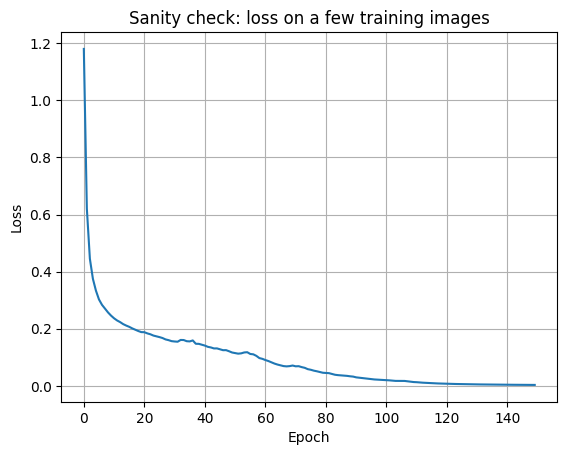

Dice (macro F1) on the overfit images: 0.730319291337911


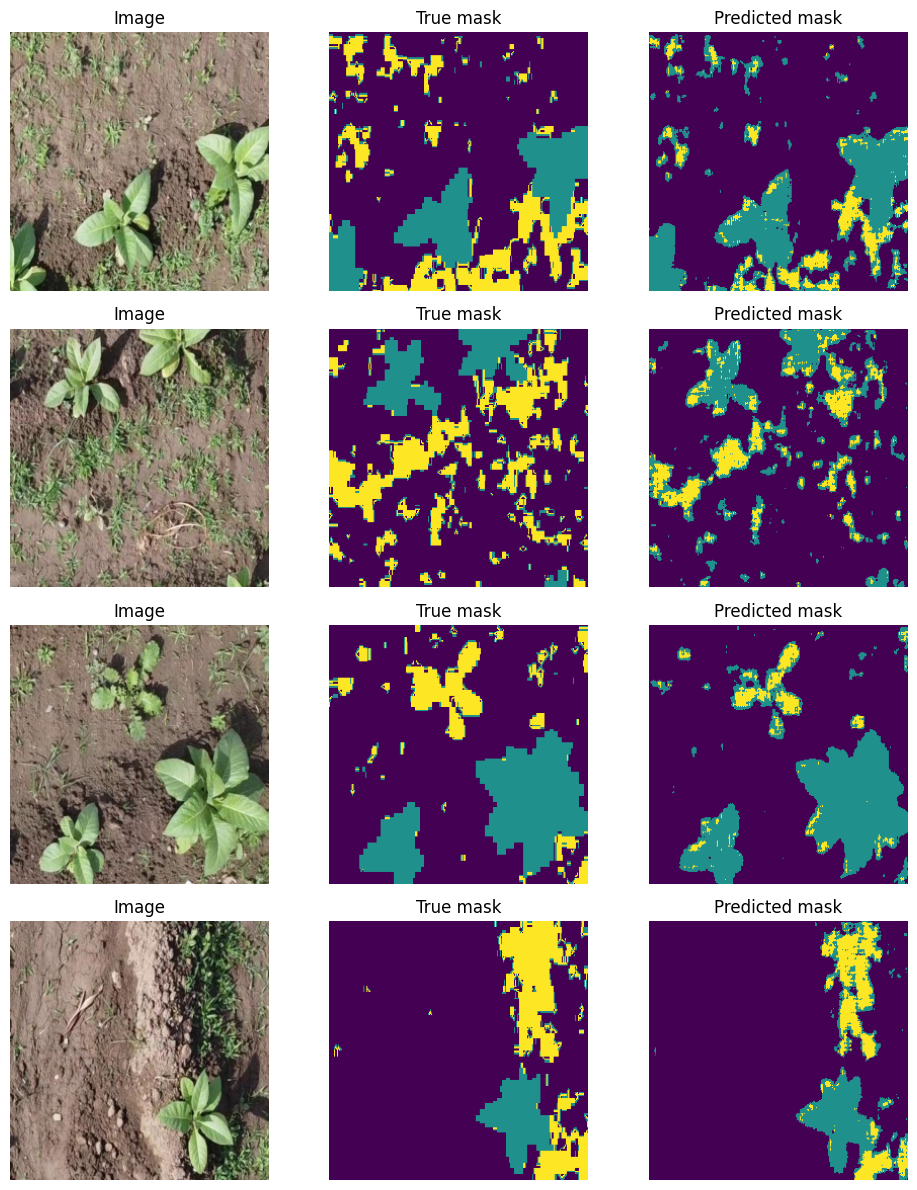

In [ ]:
SANITY_N = 4
set_seed(SEED)
tf.keras.backend.clear_session()
# Standard U-Net: 4 levels, 64 base filters
sanity_model = compile_model(build_unet(input_shape=(*IMG_SIZE, 3), depth=4, base_filters=64), "ce")
sanity_history = sanity_model.fit(
    X_train[:SANITY_N], Y_train[:SANITY_N],
    epochs=150, batch_size=2, verbose=0   # 150 epochs here; 20 is too few for 4 images
)
print("Final loss:", sanity_history.history["loss"][-1],
      "| Final pixel accuracy:", sanity_history.history["pixel_accuracy"][-1])

plt.plot(sanity_history.history["loss"])
plt.title("Sanity check: loss on a few training images")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.grid(True); plt.show()

pred = np.argmax(sanity_model.predict(X_train[:SANITY_N], verbose=0), axis=-1)
print("Dice (macro F1) on the overfit images:",
      f1_score(Y_train[:SANITY_N].reshape(-1), pred.reshape(-1), average="macro"))

fig, axes = plt.subplots(SANITY_N, 3, figsize=(10, 3*SANITY_N))
for i in range(SANITY_N):
    axes[i,0].imshow(X_train[i]); axes[i,0].set_title("Image"); axes[i,0].axis("off")
    axes[i,1].imshow(Y_train[i], vmin=0, vmax=2); axes[i,1].set_title("True mask"); axes[i,1].axis("off")
    axes[i,2].imshow(pred[i], vmin=0, vmax=2); axes[i,2].set_title("Predicted mask"); axes[i,2].axis("off")
plt.tight_layout(); plt.show()

### a. Sanity Check Diagnostic: Inference vs Training Mode

In [ ]:
# Diagnostic: compare inference mode vs training mode on the same 4 images
pred_inf = np.argmax(sanity_model.predict(X_train[:SANITY_N], verbose=0), axis=-1)
pred_trn = np.argmax(sanity_model(X_train[:SANITY_N], training=True).numpy(), axis=-1)
for name, p in [("inference mode", pred_inf), ("training mode", pred_trn)]:
    d = f1_score(Y_train[:SANITY_N].reshape(-1), p.reshape(-1), average="macro")
    print(f"{name}: Dice = {d:.4f}")

inference mode: Dice = 0.7303
training mode: Dice = 0.9960


### b. Sanity Check Fix: BatchNorm Recalibration

In [ ]:
# Recalibrate BatchNorm running statistics on the 4 sanity-check images
for _ in range(300):
    _ = sanity_model(X_train[:SANITY_N], training=True)

pred_fixed = np.argmax(sanity_model.predict(X_train[:SANITY_N], verbose=0), axis=-1)
d_fixed = f1_score(Y_train[:SANITY_N].reshape(-1), pred_fixed.reshape(-1), average="macro")
print(f"Inference mode after BatchNorm recalibration: Dice = {d_fixed:.4f}")

Inference mode after BatchNorm recalibration: Dice = 0.9920


### c. Sanity Check Result: Predicted vs True Masks

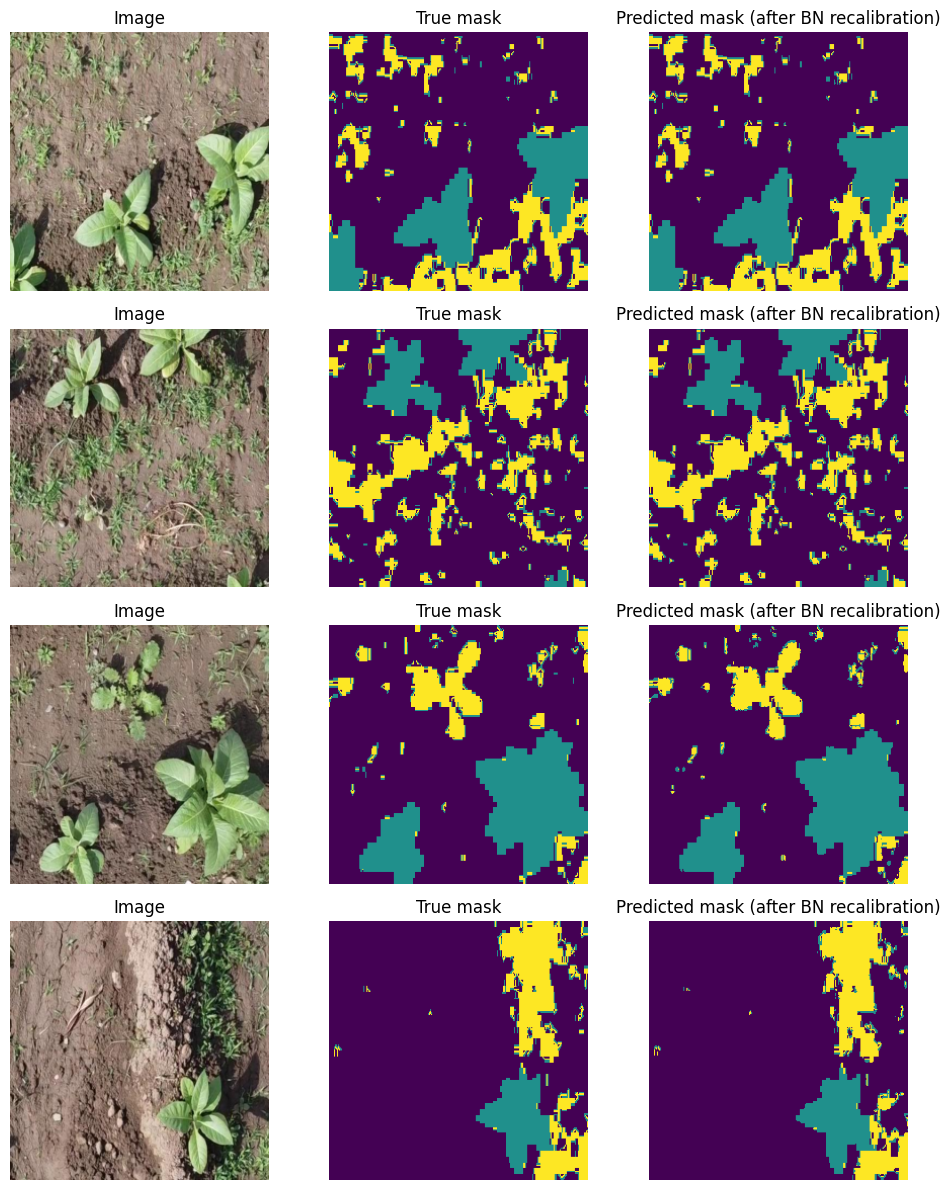

In [ ]:
pred = np.argmax(sanity_model.predict(X_train[:SANITY_N], verbose=0), axis=-1)

fig, axes = plt.subplots(SANITY_N, 3, figsize=(10, 3*SANITY_N))
for i in range(SANITY_N):
    axes[i,0].imshow(X_train[i]); axes[i,0].set_title("Image"); axes[i,0].axis("off")
    axes[i,1].imshow(Y_train[i], vmin=0, vmax=2); axes[i,1].set_title("True mask"); axes[i,1].axis("off")
    axes[i,2].imshow(pred[i], vmin=0, vmax=2); axes[i,2].set_title("Predicted mask (after BN recalibration)"); axes[i,2].axis("off")
plt.tight_layout(); plt.show()

## 10. Evaluation using Scikit-learn `f1_score` (Dice score)

In [ ]:
def evaluate_model(model, X_eval, Y_eval, label="model"):
    probabilities = model.predict(X_eval, batch_size=4, verbose=0)
    predictions = np.argmax(probabilities, axis=-1).astype(np.uint8)
    y_true_flat = Y_eval.reshape(-1)
    y_pred_flat = predictions.reshape(-1)
    # For a single class, F1 equals the Dice coefficient. Macro F1 gives equal weight to each class.
    macro_dice = f1_score(y_true_flat, y_pred_flat, labels=[0,1,2],
                          average="macro", zero_division=0)
    per_class = f1_score(y_true_flat, y_pred_flat, labels=[0,1,2],
                         average=None, zero_division=0)
    weighted = f1_score(y_true_flat, y_pred_flat, labels=[0,1,2],
                        average="weighted", zero_division=0)
    print(f"\n{label}")
    print(f"Macro Dice/F1: {macro_dice:.4f}")
    print(f"Weighted Dice/F1: {weighted:.4f}")
    print(classification_report(y_true_flat, y_pred_flat, labels=[0,1,2],
          target_names=["background","weed","wheat"], zero_division=0, digits=4))
    return {"experiment": label, "macro_dice": macro_dice, "background_dice": per_class[0],
            "weed_dice": per_class[1], "wheat_dice": per_class[2], "weighted_dice": weighted}


## 11. Objective 2 — compare U-Net depth

In [43]:
EPOCHS = 20
BATCH_SIZE = 4
results = []
histories, models = {}, {}      # saved for curves / predictions / confusion matrix

def make_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)
    ]

for depth in [1, 2, 3, 4, 5]:                      # wider range
    print(f"\n===== U-Net depth {depth} =====")
    tf.keras.backend.clear_session()
    set_seed(SEED)                                  # same seed for every run
    model = compile_model(build_unet(input_shape=(*IMG_SIZE, 3), depth=depth, base_filters=16), "ce")
    hist = model.fit(X_train, Y_train, validation_split=0.1, epochs=EPOCHS,
                     batch_size=BATCH_SIZE, callbacks=make_callbacks(), verbose=1)
    histories[f"depth{depth}"] = hist.history
    models[f"depth{depth}"] = model
    row = evaluate_model(model, X_test, Y_test, f"depth={depth}, CE, no augmentation")
    row["depth"] = depth; row["loss"] = "CE"; row["augmentation"] = "No"
    row["params"] = model.count_params(); row["epochs_run"] = len(hist.history["loss"])
    results.append(row)

import pandas as pd
depth_results = pd.DataFrame([r for r in results if r.get("depth") in [1,2,3,4,5]])
display(depth_results[["experiment","macro_dice","background_dice","weed_dice","wheat_dice","params","epochs_run"]])


===== U-Net depth 1 =====
Epoch 1/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 18s 77ms/step - loss: 0.4561 - pixel_accuracy: 0.8380 - val_loss: 0.6383 - val_pixel_accuracy: 0.7400 - learning_rate: 0.0010
Epoch 2/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 12s 72ms/step - loss: 0.3128 - pixel_accuracy: 0.8885 - val_loss: 0.3588 - val_pixel_accuracy: 0.8655 - learning_rate: 0.0010
Epoch 3/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - loss: 0.2939 - pixel_accuracy: 0.8938 - val_loss: 0.2696 - val_pixel_accuracy: 0.8996 - learning_rate: 0.0010
Epoch 4/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 12s 73ms/step - loss: 0.2829 - pixel_accuracy: 0.8974 - val_loss: 0.2494 - val_pixel_accuracy: 0.9098 - learning_rate: 0.0010
Epoch 5/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - loss: 0.2737 - pixel_accuracy: 0.9005 - val_loss: 0.2410 - val_pixel_accuracy: 0.9124 - learning_rate: 0.0010
Epoch 6/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - loss: 0.2652 - pixel_accuracy: 0.9032 - val_loss: 0.2400 - val_pixel_accuracy: 0.9119 -

,experiment,macro_dice,background_dice,weed_dice,wheat_dice,params,epochs_run
0,"depth=1, CE, no augmentation",0.870071,0.961760,0.785642,0.862812,26227,20
1,"depth=2, CE, no augmentation",0.874952,0.961443,0.793350,0.870064,118355,20
2,"depth=3, CE, no augmentation",0.876487,0.960638,0.795825,0.872998,484883,20
3,"depth=4, CE, no augmentation",0.877512,0.961731,0.796204,0.874601,1947027,20
4,"depth=5, CE, no augmentation",0.876731,0.961356,0.795281,0.873555,7787667,20


## 12. Objective 3 — compare cross-entropy vs combined CE + Dice loss

In [44]:
loss_results = []
for loss_name in ["ce", "combined"]:
    print(f"\n===== Loss: {loss_name} =====")
    tf.keras.backend.clear_session()
    set_seed(SEED)          # same seed for every run
    model = compile_model(build_unet(input_shape=(*IMG_SIZE, 3), depth=3, base_filters=16), loss_name)
    hist = model.fit(X_train, Y_train, validation_split=0.1, epochs=EPOCHS,
              batch_size=BATCH_SIZE, callbacks=make_callbacks(), verbose=1)
    histories[loss_name] = hist.history      # keys: "ce" and "combined"
    models[loss_name] = model
    row = evaluate_model(model, X_test, Y_test, f"depth=3, {loss_name}, no augmentation")
    row["depth"] = 3; row["loss"] = loss_name; row["augmentation"] = "No"
    loss_results.append(row)

loss_results_df = pd.DataFrame(loss_results)
display(loss_results_df)


===== Loss: ce =====
Epoch 1/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 36s 121ms/step - loss: 0.4132 - pixel_accuracy: 0.8596 - val_loss: 0.5632 - val_pixel_accuracy: 0.7879 - learning_rate: 0.0010
Epoch 2/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 115ms/step - loss: 0.3019 - pixel_accuracy: 0.8931 - val_loss: 0.2738 - val_pixel_accuracy: 0.9028 - learning_rate: 0.0010
Epoch 3/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 113ms/step - loss: 0.2835 - pixel_accuracy: 0.8979 - val_loss: 0.2417 - val_pixel_accuracy: 0.9105 - learning_rate: 0.0010
Epoch 4/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 111ms/step - loss: 0.2716 - pixel_accuracy: 0.9014 - val_loss: 0.2602 - val_pixel_accuracy: 0.9009 - learning_rate: 0.0010
Epoch 5/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 114ms/step - loss: 0.2623 - pixel_accuracy: 0.9040 - val_loss: 0.2375 - val_pixel_accuracy: 0.9126 - learning_rate: 0.0010
Epoch 6/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 20s 116ms/step - loss: 0.2542 - pixel_accuracy: 0.9065 - val_loss: 0.2316 - val_pixel_accuracy: 0.9156 

,experiment,macro_dice,background_dice,weed_dice,wheat_dice,weighted_dice,depth,loss,augmentation
0,"depth=3, ce, no augmentation",0.876487,0.960638,0.795825,0.872998,0.921268,3,ce,No
1,"depth=3, combined, no augmentation",0.876064,0.962335,0.795997,0.869860,0.921856,3,combined,No


## 13. Objective 4 — compare no augmentation vs augmentation

In [45]:
def augment_pair(image, mask):
    if tf.random.uniform(()) > 0.5:
        image, mask = tf.image.flip_left_right(image), tf.image.flip_left_right(mask[..., None])[..., 0]
    if tf.random.uniform(()) > 0.5:
        image, mask = tf.image.flip_up_down(image), tf.image.flip_up_down(mask[..., None])[..., 0]
    k = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    image = tf.image.rot90(image, k)
    mask = tf.image.rot90(mask[..., None], k)[..., 0]
    return image, tf.cast(mask, tf.uint8)

def make_train_dataset(images, masks, batch_size=4, augment=False, shuffle=True):
    ds = tf.data.Dataset.from_tensor_slices((images, masks))
    if shuffle:                                     # ALWAYS shuffle training data, with or without augmentation
        ds = ds.shuffle(len(images), seed=SEED, reshuffle_each_iteration=True)
    if augment:
        ds = ds.map(augment_pair, num_parallel_calls=1)   # 1 = deterministic
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

# Same validation split as Cells 26/28: the LAST 10% of X_train (what validation_split=0.1 uses)
split_at = int(len(X_train) * 0.9)
X_fit, Y_fit = X_train[:split_at], Y_train[:split_at]
X_val, Y_val = X_train[split_at:], Y_train[split_at:]

aug_results = []
for augment in [False, True]:
    print(f"\n===== Augmentation: {augment} =====")
    tf.keras.backend.clear_session()
    set_seed(SEED)
    model = compile_model(build_unet(input_shape=(*IMG_SIZE, 3), depth=3, base_filters=16), "combined")
    fit_ds = make_train_dataset(X_fit, Y_fit, BATCH_SIZE, augment=augment, shuffle=True)
    val_ds = make_train_dataset(X_val, Y_val, BATCH_SIZE, augment=False, shuffle=False)
    hist = model.fit(fit_ds, validation_data=val_ds, epochs=EPOCHS,
                     callbacks=make_callbacks(), verbose=1)
    key = "aug_yes" if augment else "aug_no"
    histories[key] = hist.history
    models[key] = model
    row = evaluate_model(model, X_test, Y_test, f"depth=3, combined loss, augmentation={augment}")
    row["depth"] = 3; row["loss"] = "CE+Dice"; row["augmentation"] = "Yes" if augment else "No"
    row["epochs_run"] = len(hist.history["loss"])
    aug_results.append(row)

aug_results_df = pd.DataFrame(aug_results)
display(aug_results_df)


===== Augmentation: False =====
Epoch 1/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 29s 119ms/step - loss: 0.7378 - pixel_accuracy: 0.8610 - val_loss: 1.0455 - val_pixel_accuracy: 0.7710 - learning_rate: 0.0010
Epoch 2/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 113ms/step - loss: 0.5459 - pixel_accuracy: 0.8957 - val_loss: 0.6215 - val_pixel_accuracy: 0.8832 - learning_rate: 0.0010
Epoch 3/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 113ms/step - loss: 0.5109 - pixel_accuracy: 0.9010 - val_loss: 0.5067 - val_pixel_accuracy: 0.9056 - learning_rate: 0.0010
Epoch 4/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 112ms/step - loss: 0.4981 - pixel_accuracy: 0.9030 - val_loss: 0.6060 - val_pixel_accuracy: 0.8849 - learning_rate: 0.0010
Epoch 5/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 114ms/step - loss: 0.4882 - pixel_accuracy: 0.9041 - val_loss: 0.5110 - val_pixel_accuracy: 0.9025 - learning_rate: 0.0010
Epoch 6/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 19s 113ms/step - loss: 0.4576 - pixel_accuracy: 0.9105 - val_loss: 0.4456 - val_pixel_accura

,experiment,macro_dice,background_dice,weed_dice,wheat_dice,weighted_dice,depth,loss,augmentation,epochs_run
0,"depth=3, combined loss, augmentation=False",0.877473,0.961429,0.797135,0.873856,0.922144,3,CE+Dice,No,20
1,"depth=3, combined loss, augmentation=True",0.875883,0.961924,0.795482,0.870242,0.921576,3,CE+Dice,Yes,20


## 14. Result of All Findings

In [46]:
all_results = pd.DataFrame(results + loss_results + aug_results)

# Make names consistent so the same run isn't listed twice (e.g. "ce" vs "CE")
all_results["experiment"] = all_results["experiment"].str.lower()
# Remove duplicate rows if cells were re-run, keeping the latest result
all_results = all_results.drop_duplicates(subset="experiment", keep="last")

display(all_results[["experiment","macro_dice","background_dice","weed_dice","wheat_dice","weighted_dice"]]
        .sort_values("macro_dice", ascending=False).reset_index(drop=True))

best = all_results.loc[all_results["macro_dice"].idxmax()]
print("\nBest observed configuration:", best["experiment"])
print(f"Macro Dice/F1 = {best['macro_dice']:.4f}")

all_results.to_csv("/content/unet_experiment_results.csv", index=False)
print("Saved results to /content/unet_experiment_results.csv")

,experiment,macro_dice,background_dice,weed_dice,wheat_dice,weighted_dice
0,"depth=4, ce, no augmentation",0.877512,0.961731,0.796204,0.874601,0.922355
1,"depth=3, combined loss, augmentation=false",0.877473,0.961429,0.797135,0.873856,0.922144
2,"depth=5, ce, no augmentation",0.876731,0.961356,0.795281,0.873555,0.921779
3,"depth=3, ce, no augmentation",0.876487,0.960638,0.795825,0.872998,0.921268
4,"depth=3, combined, no augmentation",0.876064,0.962335,0.795997,0.869860,0.921856
5,"depth=3, combined loss, augmentation=true",0.875883,0.961924,0.795482,0.870242,0.921576
6,"depth=2, ce, no augmentation",0.874952,0.961443,0.793350,0.870064,0.920920
7,"depth=1, ce, no augmentation",0.870071,0.961760,0.785642,0.862812,0.918709



Best observed configuration: depth=4, ce, no augmentation
Macro Dice/F1 = 0.8775
Saved results to /content/unet_experiment_results.csv


## 15. Training Curves

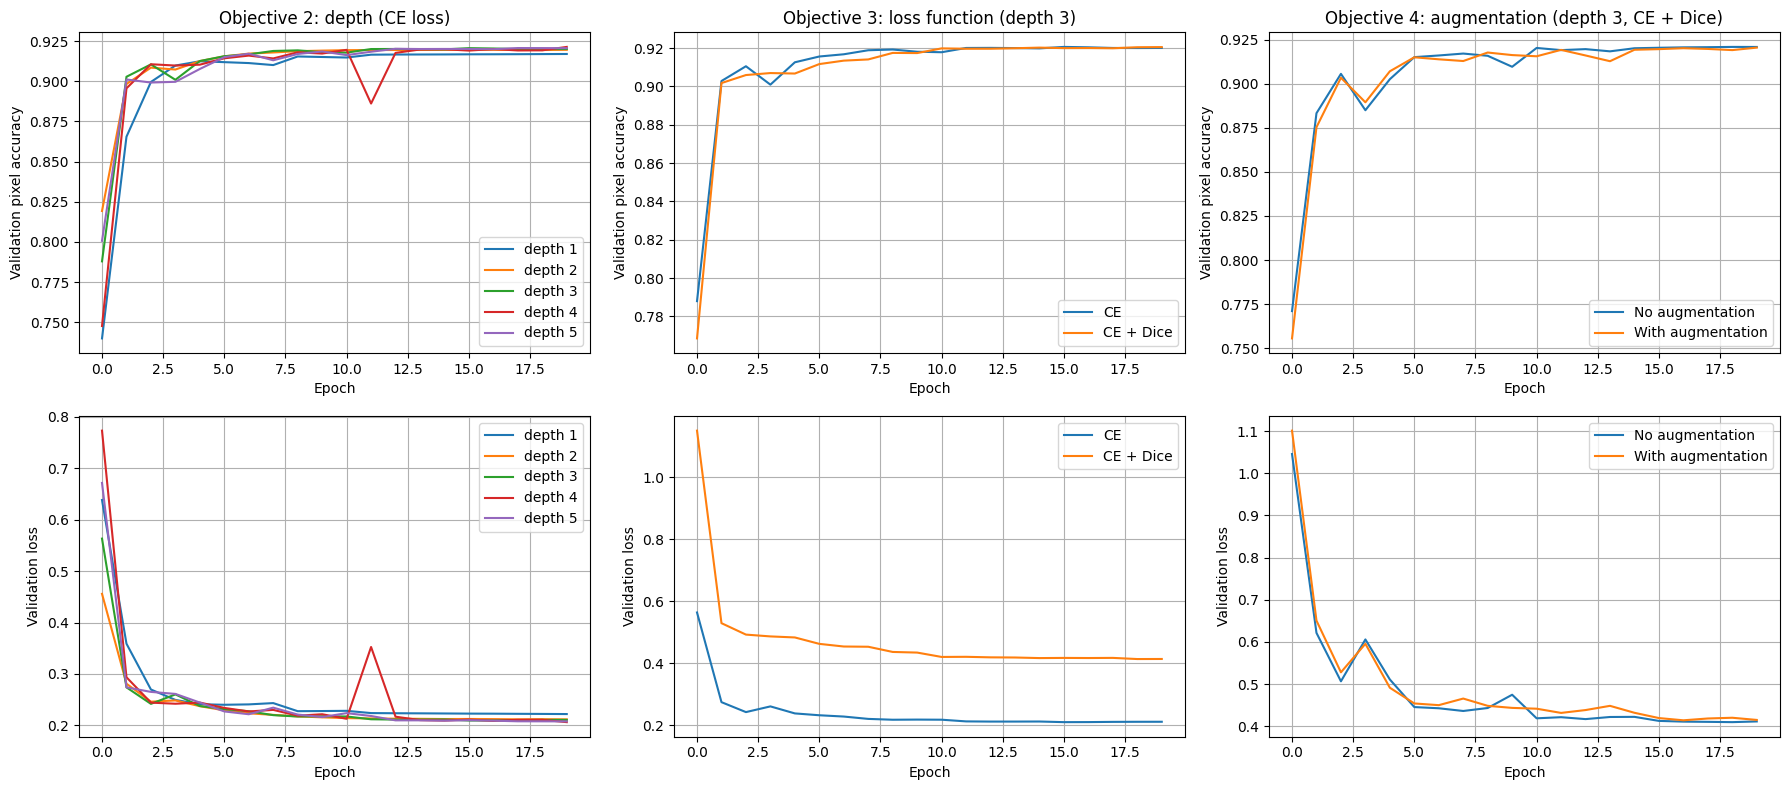

In [47]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))

groups = [
    ("Objective 2: depth (CE loss)", [(f"depth {d}", f"depth{d}") for d in [1, 2, 3, 4, 5]]),
    ("Objective 3: loss function (depth 3)", [("CE", "ce"), ("CE + Dice", "combined")]),
    ("Objective 4: augmentation (depth 3, CE + Dice)", [("No augmentation", "aug_no"), ("With augmentation", "aug_yes")]),
]

for col, (title, items) in enumerate(groups):
    for label, key in items:
        h = histories[key]
        axes[0, col].plot(h["val_pixel_accuracy"], label=label)
        axes[1, col].plot(h["val_loss"], label=label)
    axes[0, col].set_title(title)
    axes[0, col].set_ylabel("Validation pixel accuracy")
    axes[1, col].set_ylabel("Validation loss")
    for r in range(2):
        axes[r, col].set_xlabel("Epoch")
        axes[r, col].grid(True)
        axes[r, col].legend()

plt.tight_layout()
plt.show()

## 16. Example Test Prediction

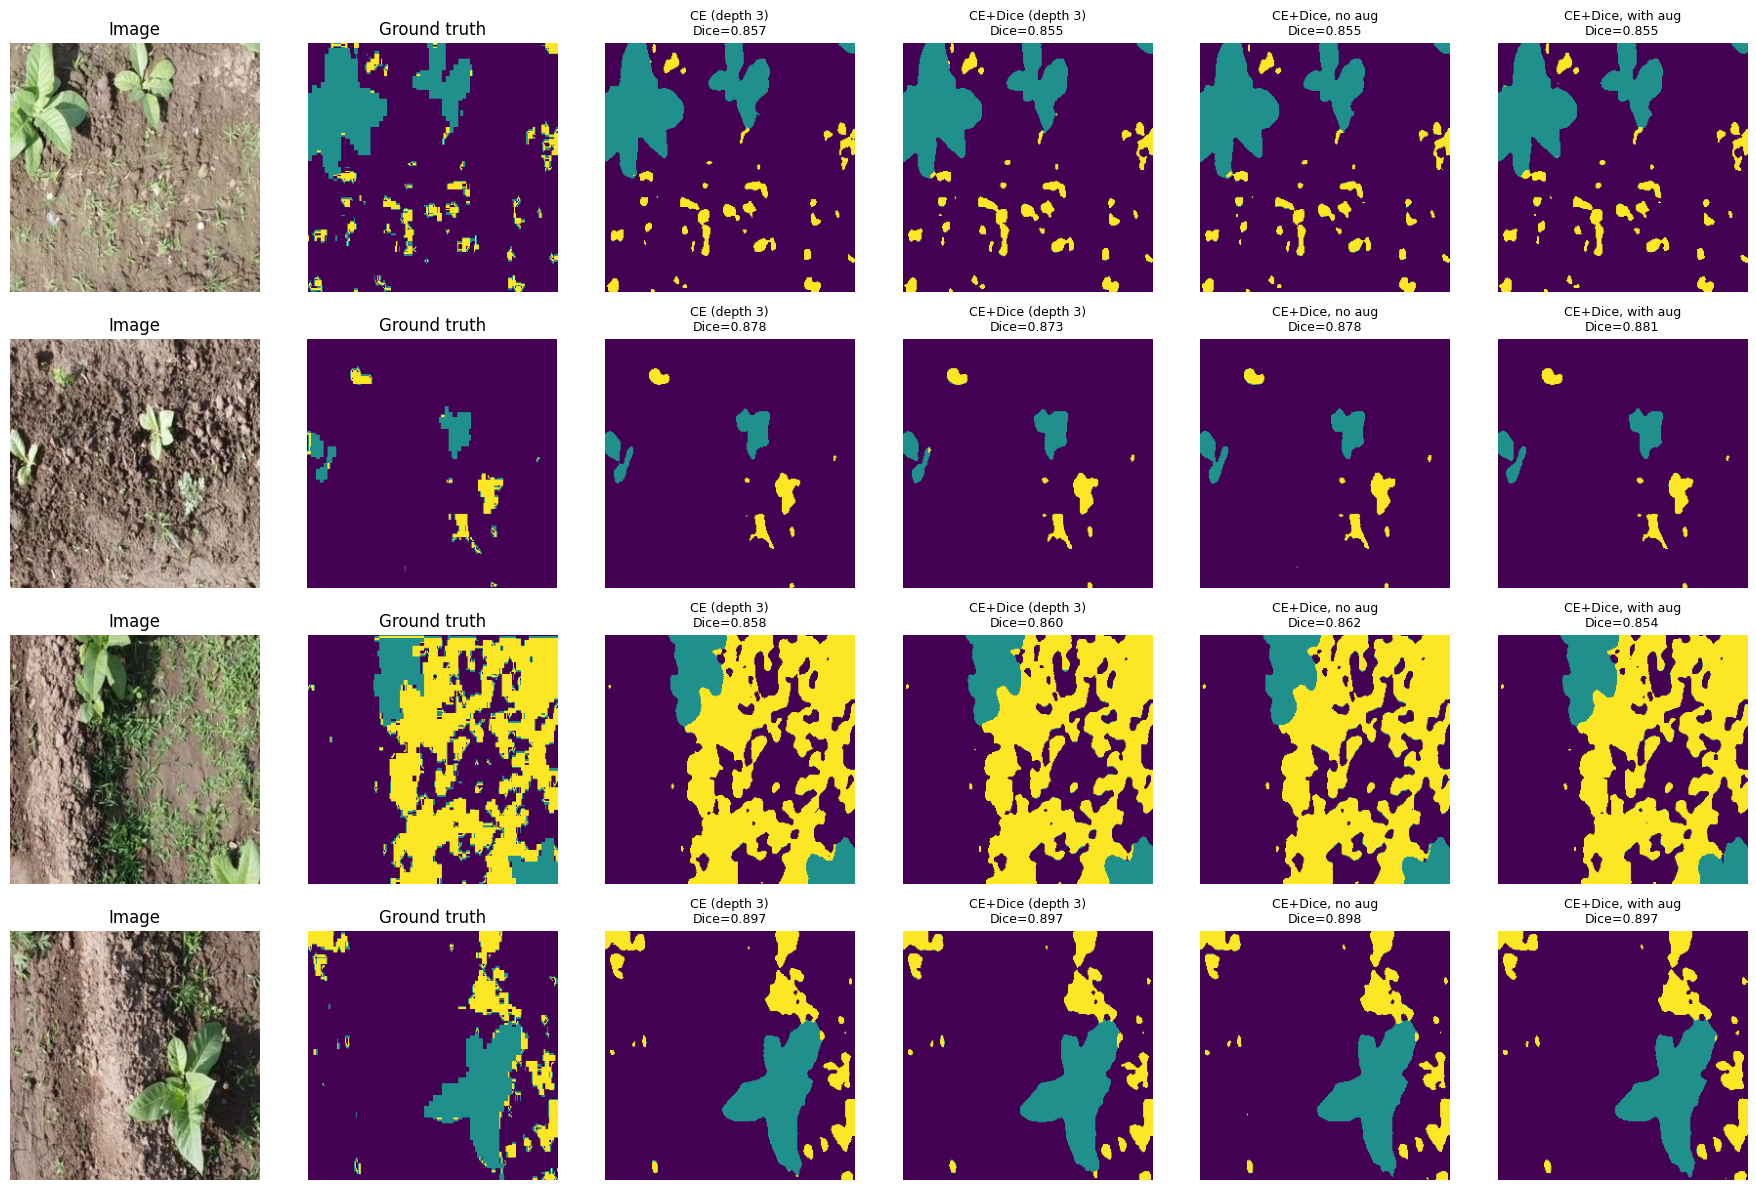

In [48]:
rng = np.random.RandomState(0)
sample_idx = rng.choice(len(X_test), 4, replace=False)

panels = [("CE (depth 3)", "ce"),
          ("CE+Dice (depth 3)", "combined"),
          ("CE+Dice, no aug", "aug_no"),
          ("CE+Dice, with aug", "aug_yes")]

preds = {key: np.argmax(models[key].predict(X_test[sample_idx], verbose=0), axis=-1)
         for _, key in panels}

ncols = 2 + len(panels)
fig, axes = plt.subplots(len(sample_idx), ncols, figsize=(3 * ncols, 3 * len(sample_idx)))

for r, i in enumerate(sample_idx):
    axes[r, 0].imshow(X_test[i]); axes[r, 0].set_title("Image")
    axes[r, 1].imshow(Y_test[i], vmin=0, vmax=2); axes[r, 1].set_title("Ground truth")
    for c, (name, key) in enumerate(panels, start=2):
        d = f1_score(Y_test[i].reshape(-1), preds[key][r].reshape(-1),
                     labels=[0, 1, 2], average="macro", zero_division=0)
        axes[r, c].imshow(preds[key][r], vmin=0, vmax=2)
        axes[r, c].set_title(f"{name}\nDice={d:.3f}", fontsize=9)
    for c in range(ncols):
        axes[r, c].axis("off")

plt.tight_layout()
plt.show()

## 17. Confusion Metrix

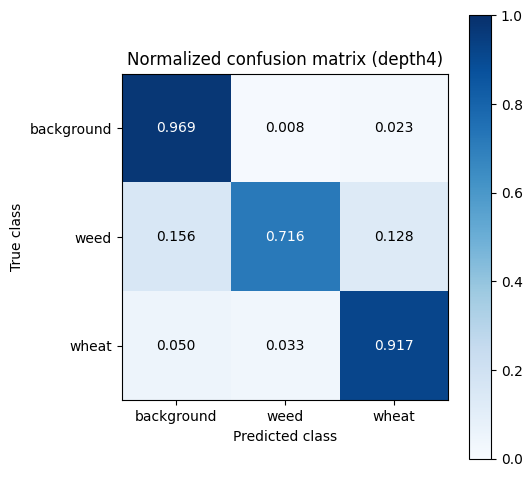

In [49]:
best_key = "depth4"      # best macro Dice in Objective 2; change to another key if you prefer
pred_all = np.argmax(models[best_key].predict(X_test, batch_size=4, verbose=0), axis=-1)

class_names = ["background", "weed", "wheat"]
cm = confusion_matrix(Y_test.reshape(-1), pred_all.reshape(-1),
                      labels=[0, 1, 2], normalize="true")   # rows sum to 1 (= recall per class)

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(class_names)
ax.set_yticks(range(3)); ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title(f"Normalized confusion matrix ({best_key})")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:.3f}", ha="center", va="center",
                color="white" if cm[i, j] > 0.5 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.show()

## 18. Final Summary of All Results

In [51]:
# ---- 1. Training-curve summary (numbers behind the curves) ----
curve_rows = []
for key, h in histories.items():
    curve_rows.append({
        "run": key,
        "epochs_run": len(h["loss"]),
        "best_epoch": int(np.argmin(h["val_loss"])) + 1,
        "best_val_loss": min(h["val_loss"]),
        "final_train_acc": h["pixel_accuracy"][-1],
        "final_val_acc": h["val_pixel_accuracy"][-1],
    })
curve_df = pd.DataFrame(curve_rows).round(4)
print("Training-curve summary")
display(curve_df)

# ---- 2. Confusion matrix as a table (rows = true class, row-normalized) ----
cm_df = pd.DataFrame(cm, index=[f"true {c}" for c in class_names],
                     columns=[f"pred {c}" for c in class_names]).round(4)
print(f"\nNormalized confusion matrix ({best_key})")
display(cm_df)
print("Per-class recall:", dict(zip(class_names, np.diag(cm).round(4))))

# ---- 3. Per-image Dice for the example test predictions ----
pred_rows = []
for r, i in enumerate(sample_idx):
    row = {"test_image_index": int(i)}
    for name, key in panels:
        row[name] = f1_score(Y_test[i].reshape(-1), preds[key][r].reshape(-1),
                             labels=[0, 1, 2], average="macro", zero_division=0)
    pred_rows.append(row)
pred_df = pd.DataFrame(pred_rows).round(4)
print("\nDice on the example test images")
display(pred_df)

# ---- 4. Save everything ----
curve_df.to_csv("/content/training_curve_summary.csv", index=False)
cm_df.to_csv("/content/confusion_matrix.csv")
pred_df.to_csv("/content/example_prediction_dice.csv", index=False)
print("\nSaved: training_curve_summary.csv, confusion_matrix.csv, example_prediction_dice.csv")

Training-curve summary


,run,epochs_run,best_epoch,best_val_loss,final_train_acc,final_val_acc
0,depth1,20,20,0.2219,0.9110,0.9170
1,depth2,20,20,0.2116,0.9139,0.9196
2,depth3,20,16,0.2093,0.9184,0.9200
3,depth4,20,20,0.2062,0.9186,0.9214
4,depth5,20,20,0.2076,0.9180,0.9206
5,ce,20,16,0.2093,0.9184,0.9200
6,combined,20,19,0.4129,0.9174,0.9205
7,aug_no,20,19,0.4099,0.9172,0.9208
8,aug_yes,20,17,0.4143,0.9158,0.9204



Normalized confusion matrix (depth4)


,pred background,pred weed,pred wheat
true background,0.9692,0.0081,0.0227
true weed,0.1561,0.7158,0.1281
true wheat,0.0504,0.0328,0.9169


Per-class recall: {'background': np.float64(0.9692), 'weed': np.float64(0.7158), 'wheat': np.float64(0.9169)}

Dice on the example test images


,test_image_index,CE (depth 3),CE+Dice (depth 3),"CE+Dice, no aug","CE+Dice, with aug"
0,107,0.8567,0.8547,0.8549,0.8547
1,45,0.8778,0.8734,0.8784,0.8807
2,160,0.8580,0.8596,0.8619,0.8535
3,63,0.8967,0.8974,0.8975,0.8972



Saved: training_curve_summary.csv, confusion_matrix.csv, example_prediction_dice.csv
